In [8]:
import numpy as np
import matplotlib.pyplot as plt
from classy import Class


In [13]:
A_VALUES= np.pi
L = 0.01
base = {
    'output': 'tCl,pCl',
    'modes' :'s', 
    #'l_max_scalars': LMAX,
    'lensing': 'no',            
    'hierarchy': 'TAM',  
    'birefringence_A' : A_VALUES,    
    'birefringence_L': L,
}


cosmo = Class()
cosmo.set(base)
cosmo.compute()
cl_TAM = cosmo.raw_cl()
cosmo.struct_cleanup()
cosmo.empty()
T_CMB = 2.7255e6  # uK



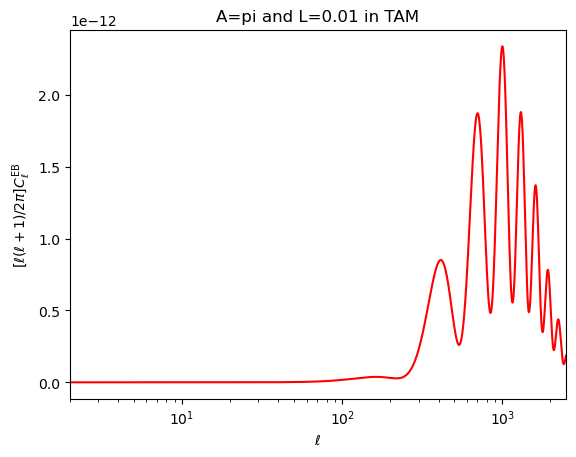

In [14]:
ell = cl_TAM['ell'][2:]
cl_EB = cl_TAM['eb'][2:]


plt.figure()

plt.xscale('log')
plt.yscale('linear')
plt.xlim(2,2500)
plt.xlabel(r'$\ell$')
plt.ylabel(r'$[\ell(\ell+1)/2\pi] C_\ell^\mathrm{EB}$')
plt.title("A=pi and L=0.01 in TAM")
plt.plot(ell,cl_EB*ell*(ell+1)/(2.*np.pi),'r-')
plt.show()


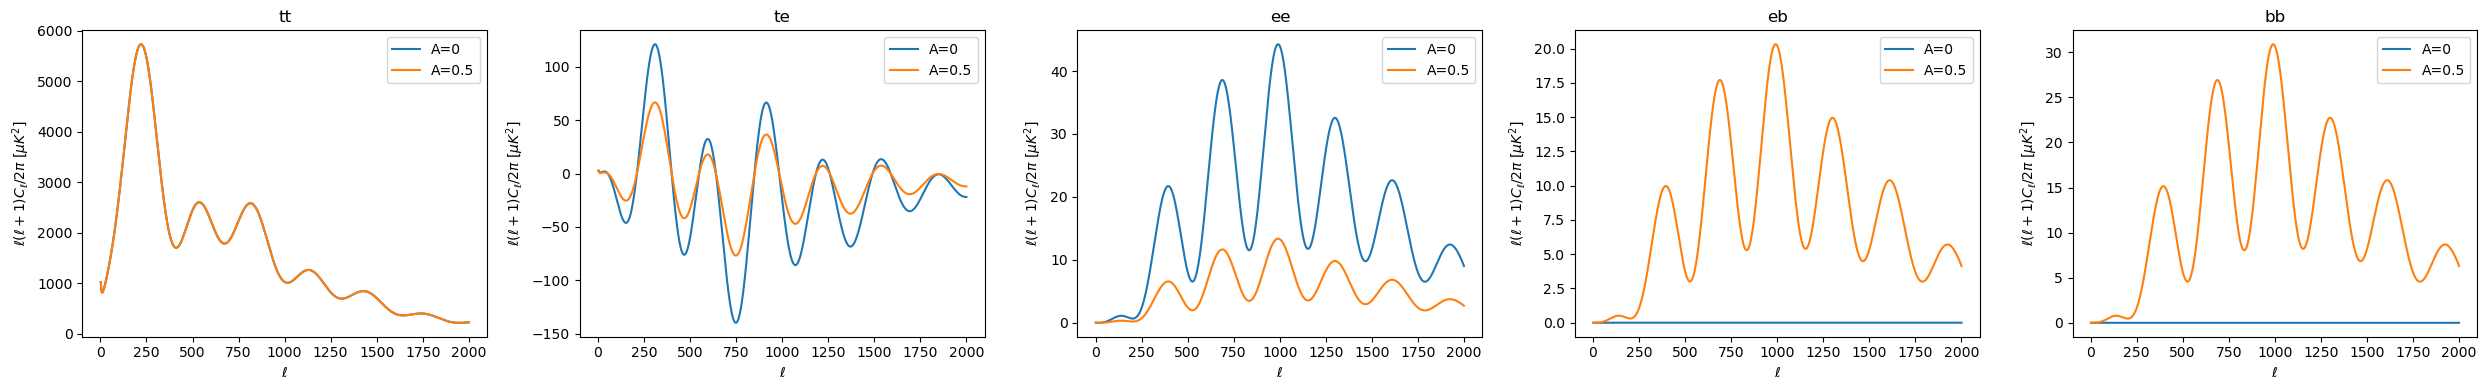

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from classy import Class


A_VALUES = [0.0, .5]        
L = 1/1509 # this is 1/tau_z=7.7 in 1/Mpc                   
LMAX = 2000


base = {
    'output': 'tCl,pCl',
    'l_max_scalars': LMAX,
    'lensing': 'no',            
    'hierarchy': 'tam',      
    'birefringence_L': L,
}

T_CMB = 2.7255e6  # uK
results_tam = {}

for A in A_VALUES:
    cosmo = Class()
    cosmo.set(base)
    cosmo.set({'birefringence_A': A})
    cosmo.compute()
    cl = cosmo.raw_cl(LMAX)
    results_tam[A] = cl
    cosmo.struct_cleanup()
    cosmo.empty()

ell = results_tam[A_VALUES[0]]['ell']
fac = ell*(ell+1)/(2*np.pi) * T_CMB**2   

fig, axes = plt.subplots(1, 5, figsize=(25, 4))
for ax, key in zip(axes, ['tt','te','ee','eb', 'bb', 'tb']): #zip is a function that pairs axes[0],eb and axes[1],bb and axes[2],tb
    for A, cl in results_tam.items(): #results_tam holds all the Cl arrays for different A values, so we loop through them
        y = fac*cl[key]
        ax.plot(ell[2:], y[2:], label=f"A={A:g}")
    ax.set_xscale('linear')
    ax.set_title(key)
    ax.set_xlabel(r'$\ell$')
    ax.set_ylabel(r'$\ell(\ell+1)C_\ell/2\pi\ [\mu K^2]$')
    ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
print(np.max(results_tam[A_VALUES[1]]['bb']))

8.834537223086726e-17


In [6]:
print(results_tam[A_VALUES[1]]['ee'])

[0.00000000e+00 0.00000000e+00 4.25085017e-15 ... 5.86251259e-19
 5.80532221e-19 5.74752248e-19]
